# Doha Flood Watch: rain-flood impact mapping for Qatar with Sentinel-1 radar

Team Stark, Qatar. Theme: Climate-induced Disasters.
Arab Youth Space Hackathon 2026, 813 Challenge, Proof of Concept.

On 20 October 2018 Doha got roughly a year's rain in one day, and roads, underpasses and buildings flooded
across the city. Qatar is flat and mostly paved or desert, so heavy rain doesn't drain away. It collects on the
surface and soaks the ground.

In this notebook we use free Sentinel-1 radar images from before and after that storm to find where the ground
got saturated. We then measure the affected area and rank 1 km cells, to give drainage, municipal and emergency
teams a list of neighbourhoods to check first.

We use radar because storms bring cloud, and optical satellites like Sentinel-2 can't see through it. In the
README we show that small cloud shadows over Doha on 22 October 2018 looked like flood water to an optical water
index. Radar works through cloud, day and night.

Running the whole notebook takes about a minute on a laptop with the sample data in the repo. It doesn't need a
GPU or any API keys.

## 1. Setup

In [1]:
import sys, json, random, warnings
warnings.filterwarnings("ignore")  # silence library deprecation noise in outputs
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import folium

# Work from the repository root whether the notebook is started from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import floodmap as fm

random.seed(42)
np.random.seed(42)

DATA_DIR = ROOT / "data" / "sample_input"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
print("Repository root found:", ROOT.name)

Repository root found: Hackathon UAE


## 2. Area of interest and dates

The area covers central Doha, Al Rayyan and the northern edge of Al Wakrah, about 22 × 22 km.

| Role | Sensor | Date | Purpose |
|---|---|---|---|
| Baseline | Sentinel-1 RTC (VV) | 2018-10-03 | Dry-weather reference to measure false alarms |
| Before | Sentinel-1 RTC (VV) | 2018-10-15 | Last radar pass before the storm |
| Storm | (no image) | 2018-10-20 | Heavy rain in Doha |
| After | Sentinel-1 RTC (VV) | 2018-10-27 | First radar pass after the storm (same orbit, same geometry) |
| Context | Sentinel-2 L2A (RGB) | 2018-10-12 | True-colour background map |
| Land cover | ESA WorldCover 2021 | 2021 map | Exposure by land-cover class, sea mask |

All three radar images were taken by the same satellite (Sentinel-1A), on the same ascending orbit, at the same
time of day (14:41 UTC). Any difference between them comes from the ground itself.

In [2]:
AOI_BBOX = [51.40, 25.18, 51.62, 25.38]   # lon_min, lat_min, lon_max, lat_max (Doha, Qatar)
S1_DATES = {"baseline": "2018-10-03", "before": "2018-10-15", "after": "2018-10-27"}
S2_DATE = "2018-10-12"

expected = [DATA_DIR / f"s1_vv_db_{k}_{d}.tif" for k, d in S1_DATES.items()] + \
           [DATA_DIR / f"s2_rgb_{S2_DATE}.tif", DATA_DIR / "worldcover_2021.tif"]

# Uses the committed sample data. Set DOWNLOAD = True to re-fetch everything from the
# Microsoft Planetary Computer (free, no account needed; ~20 s on a normal connection).
DOWNLOAD = not all(p.exists() for p in expected)
if DOWNLOAD:
    provenance = fm.download_inputs(AOI_BBOX, S1_DATES, S2_DATE, DATA_DIR)
    (DATA_DIR / "provenance.json").write_text(json.dumps(provenance, indent=2))
print("Downloaded fresh data" if DOWNLOAD else "Using committed sample data in data/sample_input/")
print(json.dumps(json.loads((DATA_DIR / "provenance.json").read_text()), indent=1))

Using committed sample data in data/sample_input/
{
 "s1_baseline": [
  "S1A_IW_GRDH_1SDV_20181003T144107_20181003T144132_023973_029E56_rtc"
 ],
 "s1_before": [
  "S1A_IW_GRDH_1SDV_20181015T144107_20181015T144132_024148_02A40E_rtc"
 ],
 "s1_after": [
  "S1A_IW_GRDH_1SDV_20181027T144107_20181027T144132_024323_02A9AE_rtc"
 ],
 "s2_rgb": [
  "S2A_MSIL2A_20181012T070821_R106_T39RWJ_20201009T104304",
  "S2A_MSIL2A_20181012T070821_R106_T39RWH_20201009T104305"
 ],
 "worldcover": [
  "ESA_WorldCover_10m_2021_v200_N24E051"
 ]
}


## 3. Load the inputs

In [3]:
vv, rgb, worldcover = fm.read_inputs(DATA_DIR, S1_DATES, S2_DATE)
wc = worldcover.values
rgb_img = np.moveaxis(rgb.values, 0, -1)
land = fm.land_mask(wc, coast_buffer_m=300)

print("Grid:", vv["before"].shape, "pixels at", fm.PIXEL_M, "m  =",
      round(vv["before"].size * fm.PIXEL_KM2, 1), "km²")
print("Land analysed (sea and 300 m shoreline buffer removed):", round(land.sum() * fm.PIXEL_KM2, 1), "km²")

Grid: (1113, 1113) pixels at 20 m  = 495.5 km²
Land analysed (sea and 300 m shoreline buffer removed): 361.1 km²


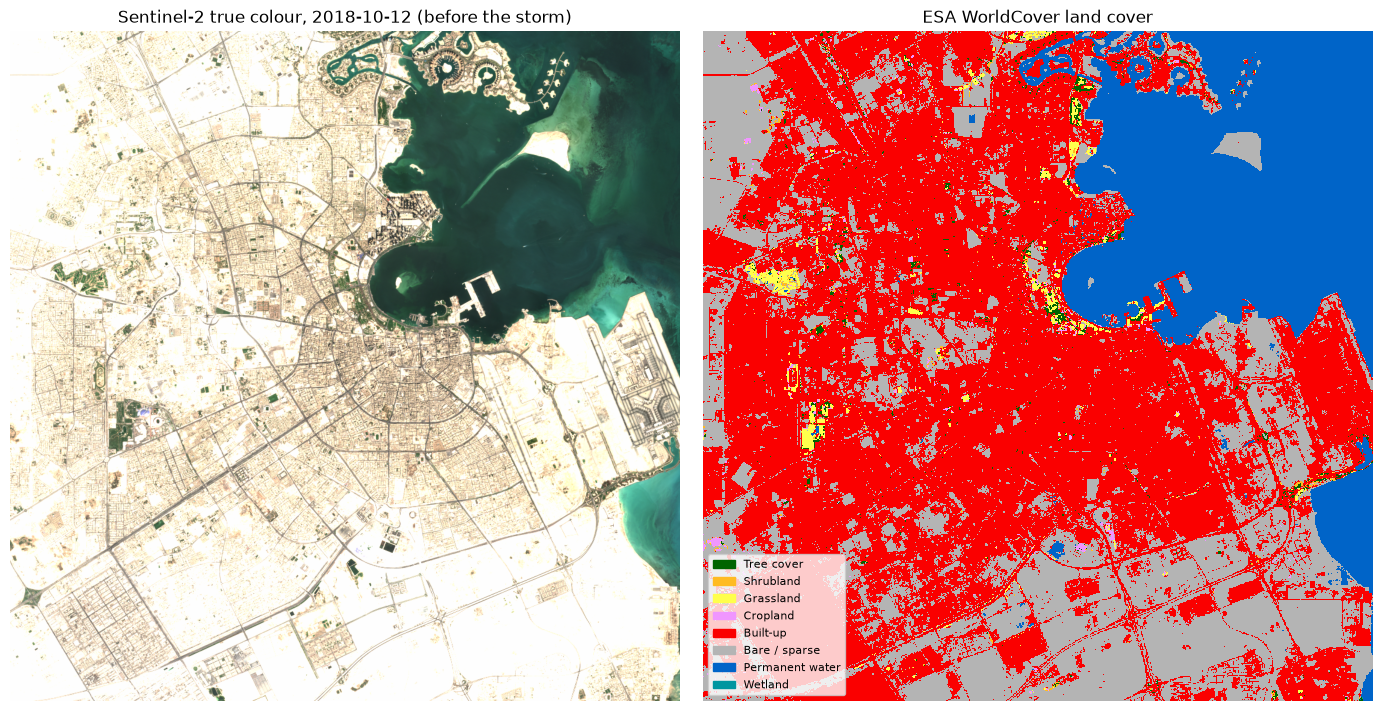

In [4]:
wc_codes = [10, 20, 30, 40, 50, 60, 80, 90]
wc_cols = ["#006400", "#ffbb22", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4", "#0064c8", "#0096a0"]
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(rgb_img); ax[0].set_title(f"Sentinel-2 true colour, {S2_DATE} (before the storm)")
ax[1].imshow(wc, cmap=ListedColormap(wc_cols), norm=BoundaryNorm(wc_codes + [100], len(wc_codes)), interpolation="nearest")
ax[1].set_title("ESA WorldCover land cover")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in wc_cols]
ax[1].legend(handles, [fm.WORLDCOVER[c] for c in wc_codes], loc="lower left", fontsize=8)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Radar change detection

Heavy rain changes a C-band radar image in two ways.

Wet ground gets brighter. Water raises the soil's dielectric constant, so wet sand, gravel, empty lots and road
shoulders send more energy back to the satellite. We mark land where VV backscatter went up by more than 3 dB,
which is roughly double.

Standing water gets darker, because a smooth water surface reflects the signal away from the satellite. We mark
land where backscatter went down by more than 3 dB and is now below −15 dB.

Before comparing, a 5 × 5 median filter reduces radar speckle.

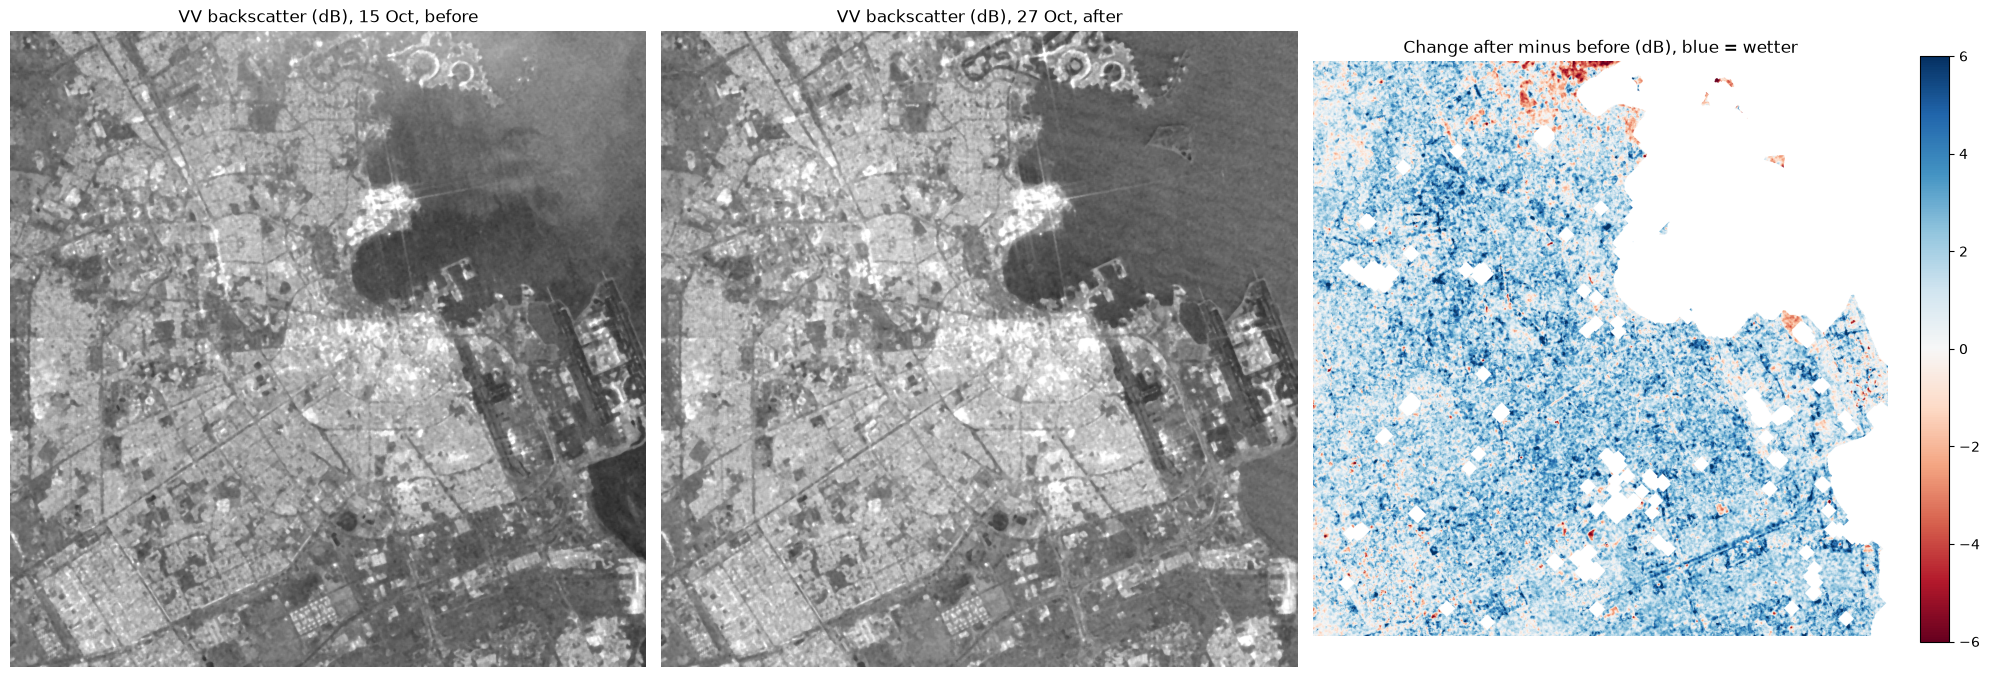

In [5]:
f = {k: fm.despeckle(v.values) for k, v in vv.items()}

fig, ax = plt.subplots(1, 3, figsize=(20, 7))
ax[0].imshow(f["before"], cmap="gray", vmin=-25, vmax=5); ax[0].set_title("VV backscatter (dB), 15 Oct, before")
ax[1].imshow(f["after"], cmap="gray", vmin=-25, vmax=5); ax[1].set_title("VV backscatter (dB), 27 Oct, after")
im = ax[2].imshow(np.where(land, f["after"] - f["before"], np.nan), cmap="RdBu", vmin=-6, vmax=6)
ax[2].set_title("Change after minus before (dB), blue = wetter")
plt.colorbar(im, ax=ax[2], fraction=0.046)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

In [6]:
WET_DB, POND_DB = 3.0, -3.0
diff, wet, pond = fm.detect_change(f["before"], f["after"], land, wet_db=WET_DB, pond_db=POND_DB)

wet_km2, pond_km2 = wet.sum() * fm.PIXEL_KM2, pond.sum() * fm.PIXEL_KM2
print(f"Rain-saturated ground: {wet_km2:6.1f} km²  ({100 * wet_km2 / (land.sum() * fm.PIXEL_KM2):.1f}% of land in the AOI)")
print(f"Standing water:        {pond_km2:6.2f} km²")

Rain-saturated ground:   57.5 km²  (15.9% of land in the AOI)
Standing water:          0.08 km²


## 5. Validation: false alarms on a dry week

There's no official flood map for this storm, so we check the detector a different way. We run the same method
on two radar images taken 12 days apart with no rain in between (3 to 15 October). Whatever it marks there is
noise from speckle, construction or irrigation. If the storm result is real, it should be much bigger than that.

In [7]:
fa_wet, fa_pond = fm.false_alarm_check(f["baseline"], f["before"], land, wet_db=WET_DB, pond_db=POND_DB)
validation = pd.DataFrame({
    "pair": ["Storm: 15 to 27 Oct", "Dry week: 3 to 15 Oct (no rain)"],
    "wet_ground_km2": [wet_km2, fa_wet],
    "standing_water_km2": [pond_km2, fa_pond],
}).round(2)
display(validation)
print(f"Signal-to-noise for wet ground: {wet_km2 / fa_wet:.1f}×  (storm vs dry week)")
print(f"Signal-to-noise for standing water: {pond_km2 / max(fa_pond, 1e-9):.1f}×")

,pair,wet_ground_km2,standing_water_km2
0,Storm: 15 to 27 Oct,57.45,0.08
1,Dry week: 3 to 15 Oct (no rain),4.55,0.06


Signal-to-noise for wet ground: 12.6×  (storm vs dry week)
Signal-to-noise for standing water: 1.4×


In [8]:
# Sensitivity: how the result and the false-alarm area move with the threshold
rows = []
for t in [2.0, 2.5, 3.0, 3.5, 4.0, 5.0]:
    _, w, _ = fm.detect_change(f["before"], f["after"], land, wet_db=t)
    fa, _ = fm.false_alarm_check(f["baseline"], f["before"], land, wet_db=t)
    rows.append({"threshold_dB": t, "storm_wet_km2": w.sum() * fm.PIXEL_KM2, "dry_week_false_km2": fa})
sens = pd.DataFrame(rows)
sens["signal_to_noise"] = sens.storm_wet_km2 / sens.dry_week_false_km2
display(sens.round(1))

,threshold_dB,storm_wet_km2,dry_week_false_km2,signal_to_noise
0,2.0,138.5,11.8,11.8
1,2.5,91.8,7.1,13.0
2,3.0,57.5,4.5,12.6
3,3.5,34.8,3.0,11.6
4,4.0,20.7,2.1,10.0
5,5.0,7.4,1.0,7.3


At every threshold from 2 to 5 dB, the storm finds 7 to 13 times more wet ground than the dry week, so the
result doesn't depend on the exact setting. We use 3 dB.

Standing water is another matter. At day seven it is about the same as the dry-week noise. By
27 October most of the surface water had been pumped away, drained or evaporated, so with a 12-day revisit we
can't measure it. The README covers this under limitations.

## 6. Exposure by land-cover type

In [9]:
exposure = fm.exposure_table(wet, pond, wc, land)
exposure.to_csv(RESULTS_DIR / "exposure_by_landcover.csv", index=False)
display(exposure)

,land_cover,class_area_km2,wet_ground_km2,standing_water_km2,wet_ground_pct
0,Built-up,236.459,42.247,0.010,17.867
1,Bare / sparse,117.380,14.656,0.062,12.486
2,Cropland,1.562,0.191,0.007,12.212
3,Grassland,2.583,0.183,0.000,7.078
4,Tree cover,2.087,0.097,0.000,4.658
5,Shrubland,1.018,0.081,0.002,7.934


## 7. Ranking 1 km cells

A pixel map is hard to act on. Someone planning inspections wants to know which neighbourhoods to visit first,
so we group the pixels into 1 km cells and rank each cell by the share of its land that is saturated.

In [10]:
grid, cells = fm.impact_grid(wet, pond, land, vv["before"], cell_m=1000)
cells.to_csv(RESULTS_DIR / "impact_grid_1km.csv", index=False)
top = cells.head(15)[["rank", "impact_pct", "wet_ha", "lat", "lon"]]
top.to_csv(RESULTS_DIR / "top15_priority_cells.csv", index=False)
display(top)

,rank,impact_pct,wet_ha,lat,lon
0,1,57.5,29.3,25.21301,51.60286
1,2,47.6,47.6,25.33996,51.45443
2,3,46.2,46.2,25.33096,51.44446
3,4,43.2,41.3,25.27672,51.46413
4,5,40.6,32.8,25.18591,51.60273
5,6,39.6,39.6,25.24053,51.48385
6,7,39.6,39.6,25.24047,51.50371
7,8,39.5,39.5,25.29481,51.45426
8,9,39.1,39.1,25.33093,51.45440
9,10,38.1,38.1,25.30378,51.47417


## 8. Final map

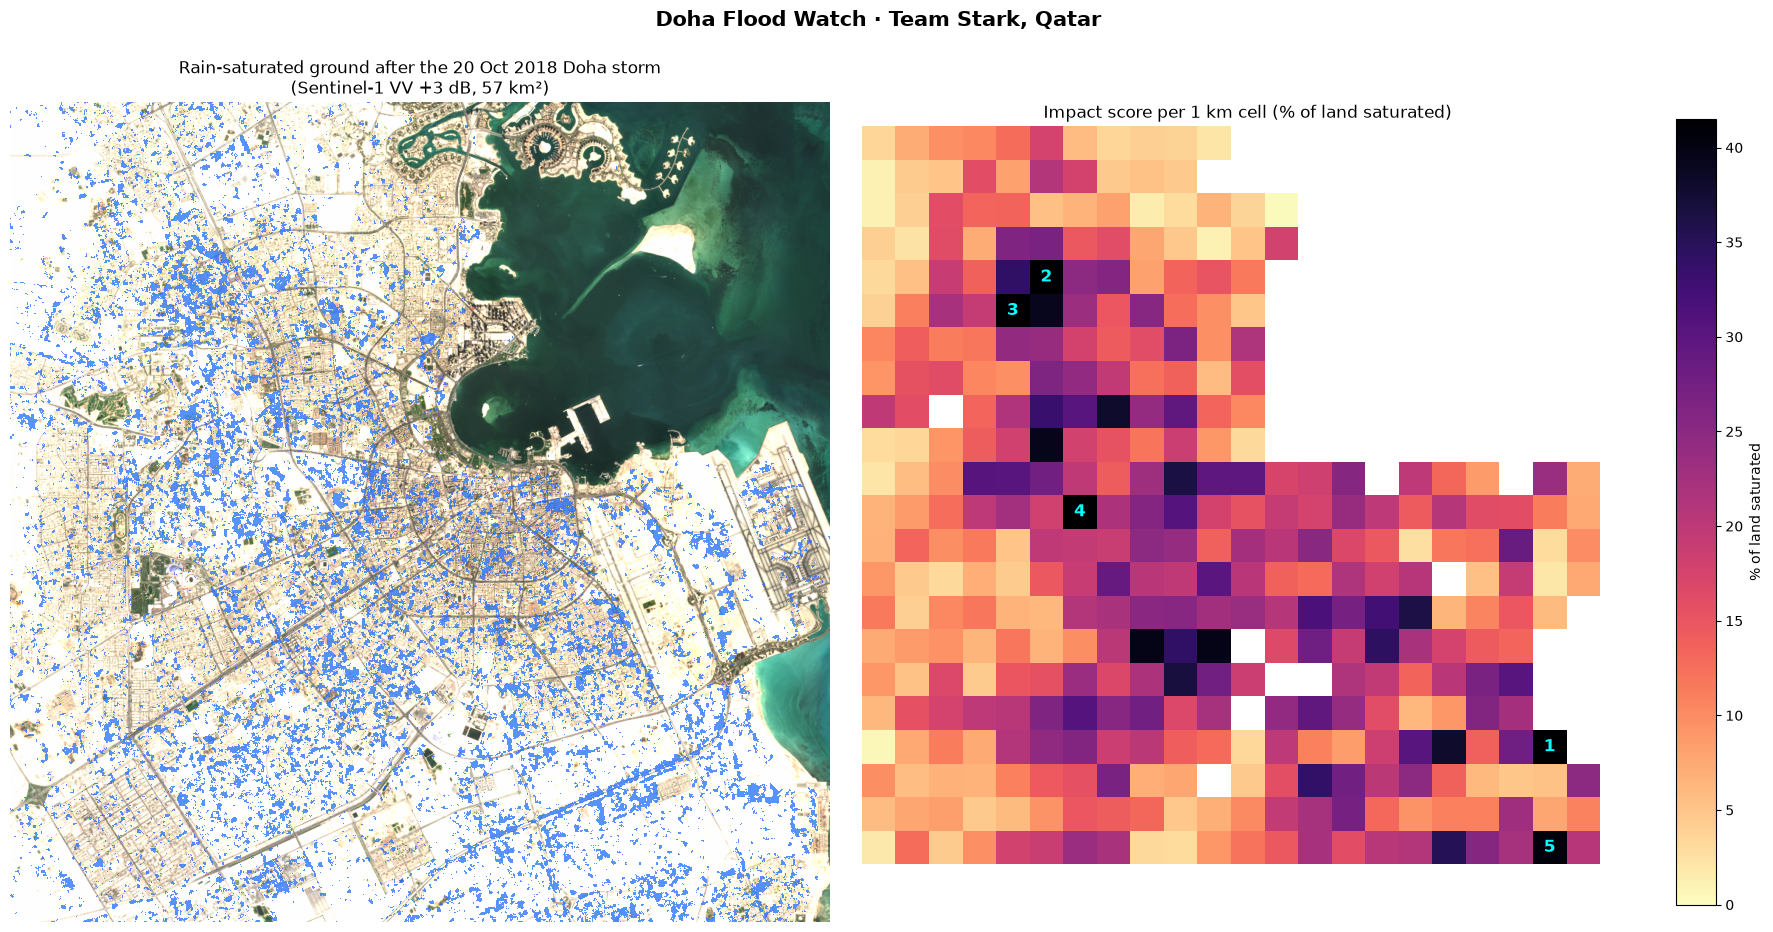

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(18, 9))
ax[0].imshow(rgb_img)
ax[0].imshow(np.ma.masked_where(~wet, wet), cmap=ListedColormap(["#1f6fff"]), alpha=0.75, interpolation="nearest")
ax[0].set_title(f"Rain-saturated ground after the 20 Oct 2018 Doha storm\n(Sentinel-1 VV +{WET_DB:.0f} dB, {wet_km2:.0f} km²)")
im = ax[1].imshow(grid, cmap="magma_r", vmin=0, vmax=np.nanpercentile(grid, 99), interpolation="nearest")
ax[1].set_title("Impact score per 1 km cell (% of land saturated)")
plt.colorbar(im, ax=ax[1], fraction=0.046, label="% of land saturated")
for _, r in cells.head(5).iterrows():  # label the top-5 priority cells
    ax[1].text(r.grid_col, r.grid_row, str(int(r["rank"])), color="cyan", ha="center", va="center", fontsize=12, weight="bold")
for a in ax: a.axis("off")
fig.suptitle("Doha Flood Watch · Team Stark, Qatar", fontsize=15, weight="bold", y=1.03)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "doha_flood_impact_map.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Interactive map

In [12]:
# Base maps that need no API key: OpenStreetMap streets, with Esri satellite imagery as an option
m = folium.Map(location=[25.28, 51.51], zoom_start=12, tiles="OpenStreetMap", control_scale=True)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri", name="Satellite (Esri)",
).add_to(m)
vmax = cells.impact_pct.quantile(0.99)
cmap = plt.get_cmap("magma_r")
grid_layer = folium.FeatureGroup(name="Impact score per 1 km cell").add_to(m)
for _, r in cells.iterrows():
    if r.impact_pct < 5:
        continue
    colour = "#%02x%02x%02x" % tuple(int(255 * c) for c in cmap(min(r.impact_pct / vmax, 1))[:3])
    folium.Rectangle(
        bounds=[[r.lat_min, r.lon_min], [r.lat_max, r.lon_max]],
        color=None, fill=True, fill_color=colour, fill_opacity=0.55,
        tooltip=f"Rank {int(r['rank'])}: {r.impact_pct:.1f}% of land saturated ({r.wet_ha:.0f} ha)",
    ).add_to(grid_layer)
top_layer = folium.FeatureGroup(name="Top 10 priority cells").add_to(m)
for _, r in cells.head(10).iterrows():
    folium.Marker([r.lat, r.lon], tooltip=f"Priority #{int(r['rank'])}: {r.impact_pct:.1f}% saturated",
                  icon=folium.DivIcon(html=f'<div style="font-weight:bold;color:#fff;background:#0F2233;border-radius:4px;padding:1px 4px;font-size:13px;width:max-content">#{int(r["rank"])}</div>')).add_to(top_layer)
folium.LayerControl(collapsed=False).add_to(m)
title = ('<div style="position:fixed;top:10px;left:50px;z-index:9999;background:rgba(255,255,255,.92);padding:8px 12px;'
         'border-radius:6px;font-family:Arial;font-size:13px;box-shadow:0 1px 4px rgba(0,0,0,.3)">'
         '<b>Doha Flood Watch</b>: rain-saturated ground after the 20 Oct 2018 storm<br>'
         'Darker cell = higher share of land saturated · Team Stark, Qatar</div>')
m.get_root().html.add_child(folium.Element(title))
m.save(str(RESULTS_DIR / "doha_flood_impact_map.html"))
m

## 10. Summary

We mapped the ground that was still saturated across Doha one week after the 20 October 2018 storm, using only
free Sentinel-1 radar data. On a dry week the same detector marks 4.5 km² instead of 57.5 km², which tells us
the storm signal is real.

The results are the affected area for each land-cover type and a ranked list of 1 km cells that could guide
drainage inspections, road checks and insurance claims. The notebook saves them to `results/`:
`doha_flood_impact_map.png`, `doha_flood_impact_map.html`, `exposure_by_landcover.csv`, `impact_grid_1km.csv`
and `top15_priority_cells.csv`.

Limitations and next steps are in the README.